# Stage 3 - Feature Engineering

## 1. Prediction Setup and Data Preparation

#### Objective
Define exactly what the demand model will predict and prepare the data in the
correct chronological order before creating time-based features.

#### Prediction Setup
Information available up to Week t will be used to predict Latent_Demand for Week t+1.

#### Reasoning
Lag features, rolling statistics and other temporal features must only use past
information. Sorting the data correctly is essential to avoid leakage across SKUs
or time periods.

In [3]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

file_path = "../data/raw/SmartMarkdown_Data_Dev_2024_2025.xlsx"

df = pd.read_excel(
    file_path,
    sheet_name="Historical_Weekly_Data"
)

print("Shape:", df.shape)
print("Unique SKUs:", df["SKU_ID"].nunique())
print("Date Range:", df["Week_Start"].min(), "to", df["Week_Start"].max())

df = pd.read_excel(
    file_path,
    sheet_name="Historical_Weekly_Data"
)

print("Shape:", df.shape)
print("Unique SKUs:", df["SKU_ID"].nunique())
print("Date Range:", df["Week_Start"].min(), "to", df["Week_Start"].max())

Shape: (4200, 30)
Unique SKUs: 40
Date Range: 2024-01-01 00:00:00 to 2025-12-29 00:00:00
Shape: (4200, 30)
Unique SKUs: 40
Date Range: 2024-01-01 00:00:00 to 2025-12-29 00:00:00


In [4]:
# ---------------------------------------------------------
# Sort by SKU and Week
# ---------------------------------------------------------
# Temporal features must be calculated separately for each SKU and in chronological order.
# ---------------------------------------------------------

df = (
    df.sort_values(
        ["SKU_ID", "Week_Start"]
    )
    .reset_index(drop=True)
)

display(
    df[
        ["SKU_ID", "Week_Start", "Latent_Demand"]
    ].head(10)
)

,SKU_ID,Week_Start,Latent_Demand
0,SKU001,2024-01-01,57
1,SKU001,2024-01-08,56
2,SKU001,2024-01-15,61
3,SKU001,2024-01-22,74
4,SKU001,2024-01-29,66
5,SKU001,2024-02-05,59
6,SKU001,2024-02-12,61
7,SKU001,2024-02-19,68
8,SKU001,2024-02-26,52
9,SKU001,2024-03-04,69


-------

## 2. Calendar Features

### Objective
Create calendar-based variables that help the model learn recurring temporal
patterns in demand.

### Reasoning
EDA showed that demand changes across weeks and event periods. Calendar features
allow the model to capture recurring seasonal behaviour.

In [5]:
# ---------------------------------------------------------
# Calendar Features
# ---------------------------------------------------------

df["Year"] = df["Week_Start"].dt.year
df["Month"] = df["Week_Start"].dt.month
df["Quarter"] = df["Week_Start"].dt.quarter
df["Week_of_Year"] = df["Week_Start"].dt.isocalendar().week.astype(int)

In [6]:
display(
    df[
        [
            "Week_Start",
            "Year",
            "Month",
            "Quarter",
            "Week_of_Year"
        ]
    ].head(15)
)

,Week_Start,Year,Month,Quarter,Week_of_Year
0,2024-01-01,2024,1,1,1
1,2024-01-08,2024,1,1,2
2,2024-01-15,2024,1,1,3
3,2024-01-22,2024,1,1,4
4,2024-01-29,2024,1,1,5
5,2024-02-05,2024,2,1,6
6,2024-02-12,2024,2,1,7
7,2024-02-19,2024,2,1,8
8,2024-02-26,2024,2,1,9
9,2024-03-04,2024,3,1,10


------------

## 3. Historical Demand Features

### Objective
Create lag and rolling demand features that summarize recent SKU-level demand behaviour.

### Reasoning
Future demand is often related to recent historical demand. Lag and rolling features
allow the model to capture short-term momentum, recent average demand and variability.

All temporal features must be created separately within each SKU and must use only
past information to avoid data leakage.

- Lag_1_Demand -> demand 1 week ago
- Lag_2_Demand -> demand 2 weeks ago
- Lag_4_Demand -> demand 4 weeks ago

In [7]:
# ---------------------------------------------------------
# Lag Features
# ---------------------------------------------------------
# Historical demand values from previous weeks. Created separately within each SKU.
# ---------------------------------------------------------

df["Lag_1_Demand"] = (
    df.groupby("SKU_ID")["Latent_Demand"]
    .shift(1)
)

df["Lag_2_Demand"] = (
    df.groupby("SKU_ID")["Latent_Demand"]
    .shift(2)
)

df["Lag_4_Demand"] = (
    df.groupby("SKU_ID")["Latent_Demand"]
    .shift(4)
)

In [8]:
display(
    df.loc[
        df["SKU_ID"] == "SKU001",
        [
            "Week_Start",
            "Latent_Demand",
            "Lag_1_Demand",
            "Lag_2_Demand",
            "Lag_4_Demand"
        ]
    ].head(10)
)

,Week_Start,Latent_Demand,Lag_1_Demand,Lag_2_Demand,Lag_4_Demand
0,2024-01-01,57,NaN,NaN,NaN
1,2024-01-08,56,57.0,NaN,NaN
2,2024-01-15,61,56.0,57.0,NaN
3,2024-01-22,74,61.0,56.0,NaN
4,2024-01-29,66,74.0,61.0,57.0
5,2024-02-05,59,66.0,74.0,56.0
6,2024-02-12,61,59.0,66.0,61.0
7,2024-02-19,68,61.0,59.0,74.0
8,2024-02-26,52,68.0,61.0,66.0
9,2024-03-04,69,52.0,68.0,59.0


In [9]:
# ---------------------------------------------------------
# Rolling Demand Features
# ---------------------------------------------------------
# Shift first so the current week's demand is excluded.
# ---------------------------------------------------------

df["Rolling_4W_Avg_Demand"] = (
    df.groupby("SKU_ID")["Latent_Demand"]
    .transform(
        lambda x: x.shift(1).rolling(4).mean()
    )
)

df["Rolling_8W_Avg_Demand"] = (
    df.groupby("SKU_ID")["Latent_Demand"]
    .transform(
        lambda x: x.shift(1).rolling(8).mean()
    )
)

df["Rolling_4W_Std_Demand"] = (
    df.groupby("SKU_ID")["Latent_Demand"]
    .transform(
        lambda x: x.shift(1).rolling(4).std()
    )
)

In [10]:
display(
    df.loc[
        df["SKU_ID"] == "SKU001",
        [
            "Week_Start",
            "Latent_Demand",
            "Lag_1_Demand",
            "Rolling_4W_Avg_Demand",
            "Rolling_8W_Avg_Demand",
            "Rolling_4W_Std_Demand"
        ]
    ].head(15)
)

,Week_Start,Latent_Demand,Lag_1_Demand,Rolling_4W_Avg_Demand,Rolling_8W_Avg_Demand,Rolling_4W_Std_Demand
0,2024-01-01,57,NaN,NaN,NaN,NaN
1,2024-01-08,56,57.0,NaN,NaN,NaN
2,2024-01-15,61,56.0,NaN,NaN,NaN
3,2024-01-22,74,61.0,NaN,NaN,NaN
4,2024-01-29,66,74.0,62.00,NaN,8.286535
5,2024-02-05,59,66.0,64.25,NaN,7.675719
6,2024-02-12,61,59.0,65.00,NaN,6.683313
7,2024-02-19,68,61.0,65.00,NaN,6.683313
8,2024-02-26,52,68.0,63.50,62.750,4.203173
9,2024-03-04,69,52.0,60.00,62.125,6.582806


In [11]:
temporal_features = [
    "Lag_1_Demand",
    "Lag_2_Demand",
    "Lag_4_Demand",
    "Rolling_4W_Avg_Demand",
    "Rolling_8W_Avg_Demand",
    "Rolling_4W_Std_Demand"
]

display(
    df[temporal_features]
    .isnull()
    .sum()
    .to_frame("Missing_Count")
)

,Missing_Count
Lag_1_Demand,40
Lag_2_Demand,80
Lag_4_Demand,160
Rolling_4W_Avg_Demand,160
Rolling_8W_Avg_Demand,320
Rolling_4W_Std_Demand,160


### Feature Engineering Check - Historical Demand Features

- Lag features correctly represent demand from previous weeks within each SKU.
- Rolling averages and rolling standard deviation use only past demand because shifting is applied before rolling.
- Missing values in the initial weeks of each SKU are expected and are caused by insufficient historical observations.
- These structural missing values will be handled later when preparing the final modelling dataset.

----------

## 4. Pricing and Competitor Features

### Objective
Create pricing features that describe the product's markdown level and its
price position relative to MRP and competitors.

### Reasoning
EDA showed that discount level has a meaningful relationship with demand,
while competitor pricing provides an additional market signal. Derived pricing
features can represent these relationships more clearly than raw prices alone.

In [12]:
# ---------------------------------------------------------
# Price Index
# ---------------------------------------------------------
# Example:
# Price_Index = 0.80 means the product sells at 80% of MRP.
# ---------------------------------------------------------

df["Price_Index"] = ( df["Selling_Price"] / df["MRP"] )

In [13]:
# ---------------------------------------------------------
# Competitor Price Gap
# ---------------------------------------------------------
# Positive -> our price is higher than competitor
# Negative -> our price is lower than competitor
# ---------------------------------------------------------

df["Competitor_Gap_Pct"] = ( (df["Selling_Price"] - df["Competitor_Price"]) / df["Competitor_Price"] * 100 )

In [14]:
# ---------------------------------------------------------
# Unit Margin
# ---------------------------------------------------------
# Profit contribution earned per unit sold.
# ---------------------------------------------------------

df["Unit_Margin"] = (
    df["Selling_Price"]
    - df["Unit_Cost"]
)

In [15]:
display(
    df[
        [
            "SKU_ID",
            "Week_Start",
            "MRP",
            "Selling_Price",
            "Discount_Pct",
            "Price_Index",
            "Competitor_Price",
            "Competitor_Gap_Pct",
            "Unit_Margin"
        ]
    ].head(15)
)

,SKU_ID,Week_Start,MRP,Selling_Price,Discount_Pct,Price_Index,Competitor_Price,Competitor_Gap_Pct,Unit_Margin
0,SKU001,2024-01-01,799,719.10,10,0.90,639.20,12.500000,379.10
1,SKU001,2024-01-08,799,799.00,0,1.00,799.00,0.000000,459.00
2,SKU001,2024-01-15,799,719.10,10,0.90,719.10,0.000000,379.10
3,SKU001,2024-01-22,799,639.20,20,0.80,639.20,0.000000,299.20
4,SKU001,2024-01-29,799,679.15,15,0.85,679.15,0.000000,339.15
5,SKU001,2024-02-05,799,759.05,5,0.95,759.05,0.000000,419.05
6,SKU001,2024-02-12,799,679.15,15,0.85,759.05,-10.526316,339.15
7,SKU001,2024-02-19,799,519.35,35,0.65,519.35,0.000000,179.35
8,SKU001,2024-02-26,799,759.05,5,0.95,799.00,-5.000000,419.05
9,SKU001,2024-03-04,799,599.25,25,0.75,599.25,0.000000,259.25


In [16]:
pricing_features = [
    "Price_Index",
    "Competitor_Gap_Pct",
    "Unit_Margin"
]

display(df[pricing_features].describe().T.round(2))

,count,mean,std,min,25%,50%,75%,max
Price_Index,4200.0,0.86,0.12,0.60,0.75,0.85,0.95,1.00
Competitor_Gap_Pct,4200.0,0.41,7.01,-14.29,-5.00,0.00,5.56,15.38
Unit_Margin,4200.0,1063.81,931.51,59.40,526.50,899.10,1299.15,7599.00


### Feature Engineering Check — Pricing Features

- Price_Index correctly represents the selling price as a proportion of MRP.
- Competitor_Gap_Pct captures whether our product is cheaper or more expensive than the competitor.
- Unit_Margin remains positive across all observations.
- Price_Index and Discount_Pct contain similar information, so final feature selection may retain only one of them depending on model behaviour.

-----------

## 5. Inventory Features

### Objective
Create inventory-related features that represent how much stock is available
relative to recent demand.

### Reasoning
EDA showed that high inventory does not automatically mean overstock.
Inventory should be evaluated relative to product demand and sales velocity.
These features will later support both demand modelling and the markdown
decision engine.

In [18]:
# ---------------------------------------------------------
# Sell-Through
# ---------------------------------------------------------
# Measures the proportion of available inventory sold
# during the week.
# ---------------------------------------------------------

df["Sell_Through"] = np.where(df["Available_Inventory"] > 0, df["Units_Sold"] / df["Available_Inventory"], 0)

In [19]:
# ---------------------------------------------------------
# Weeks of Supply
# ---------------------------------------------------------
# Current inventory divided by recent average weekly demand.
# Uses historical rolling demand to avoid leakage.
# ---------------------------------------------------------

df["Weeks_of_Supply"] = np.where(
    df["Rolling_4W_Avg_Demand"] > 0,
    df["Closing_Inventory"] / df["Rolling_4W_Avg_Demand"],
    np.nan
)

In [20]:
# ---------------------------------------------------------
# Inventory Pressure
# ---------------------------------------------------------
# Higher values indicate more inventory relative to
# recent weekly demand.
# ---------------------------------------------------------

df["Inventory_Pressure"] = (df["Closing_Inventory"] / (df["Rolling_4W_Avg_Demand"] + 1))

In [21]:
display(
    df[
        [
            "SKU_ID",
            "Week_Start",
            "Units_Sold",
            "Available_Inventory",
            "Closing_Inventory",
            "Rolling_4W_Avg_Demand",
            "Sell_Through",
            "Weeks_of_Supply",
            "Inventory_Pressure"
        ]
    ].head(15)
)

,SKU_ID,Week_Start,Units_Sold,Available_Inventory,Closing_Inventory,Rolling_4W_Avg_Demand,Sell_Through,Weeks_of_Supply,Inventory_Pressure
0,SKU001,2024-01-01,57,412,361,NaN,0.138350,NaN,NaN
1,SKU001,2024-01-08,56,361,310,NaN,0.155125,NaN,NaN
2,SKU001,2024-01-15,61,310,254,NaN,0.196774,NaN,NaN
3,SKU001,2024-01-22,74,254,184,NaN,0.291339,NaN,NaN
4,SKU001,2024-01-29,66,184,123,62.00,0.358696,1.983871,1.952381
5,SKU001,2024-02-05,59,422,368,64.25,0.139810,5.727626,5.639847
6,SKU001,2024-02-12,61,368,313,65.00,0.165761,4.815385,4.742424
7,SKU001,2024-02-19,68,313,249,65.00,0.217252,3.830769,3.772727
8,SKU001,2024-02-26,52,249,202,63.50,0.208835,3.181102,3.131783
9,SKU001,2024-03-04,69,202,137,60.00,0.341584,2.283333,2.245902


In [23]:
inventory_features = [
    "Sell_Through",
    "Weeks_of_Supply",
    "Inventory_Pressure"
]

display(df[inventory_features].describe().T.round(2))

,count,mean,std,min,25%,50%,75%,max
Sell_Through,4200.0,0.27,0.16,0.0,0.17,0.23,0.32,1.00
Weeks_of_Supply,4040.0,3.39,1.68,0.0,2.09,3.31,4.64,8.57
Inventory_Pressure,4040.0,3.29,1.62,0.0,2.02,3.22,4.50,8.06


### Feature Engineering Check — Inventory Features

- Sell_Through is correctly bounded between 0 and 1.
- Weeks_of_Supply and Inventory_Pressure are non-negative and represent inventory relative to recent demand.
- Missing values in the first four weeks of each SKU are expected because the rolling demand history is not yet available.
- Weeks_of_Supply and Inventory_Pressure may contain similar information and will be reviewed later for redundancy.

----------

## 6. Customer Interest Features

### Objective
Create historical customer-interest features using product views and cart additions.

### Reasoning
EDA showed that Views and Cart_Adds are strongly associated with demand.
To avoid leakage, lagged customer-interest values are used so that only
information available from completed weeks contributes to future demand prediction.

In [24]:
# ---------------------------------------------------------
# Lagged Customer Interest Features
# ---------------------------------------------------------

df["Lag_1_Views"] = (
    df.groupby("SKU_ID")["Views"]
    .shift(1)
)

df["Lag_1_Cart_Adds"] = (
    df.groupby("SKU_ID")["Cart_Adds"]
    .shift(1)
)

In [25]:
# ---------------------------------------------------------
# Rolling Customer Interest
# ---------------------------------------------------------
# Shift first to exclude the current week's information.
# ---------------------------------------------------------

df["Rolling_4W_Avg_Views"] = (
    df.groupby("SKU_ID")["Views"]
    .transform(
        lambda x: x.shift(1).rolling(4).mean()
    )
)

df["Rolling_4W_Avg_Cart_Adds"] = (
    df.groupby("SKU_ID")["Cart_Adds"]
    .transform(
        lambda x: x.shift(1).rolling(4).mean()
    )
)

In [26]:
display(
    df.loc[
        df["SKU_ID"] == "SKU001",
        [
            "Week_Start",
            "Views",
            "Lag_1_Views",
            "Rolling_4W_Avg_Views",
            "Cart_Adds",
            "Lag_1_Cart_Adds",
            "Rolling_4W_Avg_Cart_Adds"
        ]
    ].head(12)
)

,Week_Start,Views,Lag_1_Views,Rolling_4W_Avg_Views,Cart_Adds,Lag_1_Cart_Adds,Rolling_4W_Avg_Cart_Adds
0,2024-01-01,1243,NaN,NaN,99,NaN,NaN
1,2024-01-08,1325,1243.0,NaN,208,99.0,NaN
2,2024-01-15,994,1325.0,NaN,144,208.0,NaN
3,2024-01-22,1309,994.0,NaN,122,144.0,NaN
4,2024-01-29,1291,1309.0,1217.75,187,122.0,143.25
5,2024-02-05,756,1291.0,1229.75,67,187.0,165.25
6,2024-02-12,1371,756.0,1087.50,207,67.0,130.00
7,2024-02-19,1245,1371.0,1181.75,188,207.0,145.75
8,2024-02-26,1165,1245.0,1165.75,139,188.0,162.25
9,2024-03-04,1258,1165.0,1134.25,181,139.0,150.25


In [27]:
interest_features = [
    "Lag_1_Views",
    "Lag_1_Cart_Adds",
    "Rolling_4W_Avg_Views",
    "Rolling_4W_Avg_Cart_Adds"
]

display(
    df[interest_features]
    .isnull()
    .sum()
    .to_frame("Missing_Count")
)

,Missing_Count
Lag_1_Views,40
Lag_1_Cart_Adds,40
Rolling_4W_Avg_Views,160
Rolling_4W_Avg_Cart_Adds,160


### Feature Engineering Check — Customer Interest Features

- Lagged Views and Cart_Adds correctly use only previous-week information.
- Four-week rolling averages correctly exclude the current week through shifting.
- Missing values in the initial weeks of each SKU are expected and represent insufficient historical observations.
- These historical engagement features are suitable candidates for next-week demand forecasting.

---------------

## 7. Target Creation — Next-Week Demand

### Objective
Create the next-week demand target for supervised regression.

### Reasoning
The model should use information available up to the current week to predict
unconstrained customer demand for the following week.

The target is therefore created by shifting Latent_Demand one week forward
within each SKU.

In [29]:
# ---------------------------------------------------------
# Next-Week Demand Target
# ---------------------------------------------------------

df["Future_Latent_Demand"] = (
    df.groupby("SKU_ID")["Latent_Demand"].shift(-1)
)

In [30]:
display(
    df.loc[
        df["SKU_ID"] == "SKU001",
        [
            "Week_Start",
            "Latent_Demand",
            "Future_Latent_Demand"
        ]
    ].tail(10)
)

,Week_Start,Latent_Demand,Future_Latent_Demand
95,2025-10-27,69,72.0
96,2025-11-03,72,56.0
97,2025-11-10,56,52.0
98,2025-11-17,52,87.0
99,2025-11-24,87,75.0
100,2025-12-01,75,70.0
101,2025-12-08,70,80.0
102,2025-12-15,80,79.0
103,2025-12-22,79,63.0
104,2025-12-29,63,NaN


In [31]:
print(
    "Missing Future_Latent_Demand:",
    df["Future_Latent_Demand"].isnull().sum()
)

Missing Future_Latent_Demand: 40


In [32]:
display(
    df.loc[
        df["SKU_ID"] == "SKU001",
        [
            "Week_Start",
            "Latent_Demand",
            "Future_Latent_Demand"
        ]
    ].head(8)
)

,Week_Start,Latent_Demand,Future_Latent_Demand
0,2024-01-01,57,56.0
1,2024-01-08,56,61.0
2,2024-01-15,61,74.0
3,2024-01-22,74,66.0
4,2024-01-29,66,59.0
5,2024-02-05,59,61.0
6,2024-02-12,61,68.0
7,2024-02-19,68,52.0


### Feature Engineering Check — Target Creation

- Future_Latent_Demand correctly represents the following week's latent demand within each SKU.
- The target is aligned chronologically and does not mix observations across products.
- Exactly 40 target values are missing, corresponding to the final observation of each SKU where no future week exists.
- These final rows will be excluded from supervised model training because the target is unavailable.

--------------

## 8. Feature Availability and Leakage Audit

### Objective
Review candidate predictors and ensure that only information available at the
prediction point is used to forecast next-week demand.

### Reasoning
The model predicts demand for Week t+1 using information available up to Week t.
Variables that contain future information or target-period outcomes would create
data leakage and artificially inflate model performance.

In [83]:
# ---------------------------------------------------------
# Candidate Feature Groups
# ---------------------------------------------------------

identifier_features = [
    "SKU_ID",
    "Category",
    "Subcategory",
    "Brand"
]

# calendar_features = [
#     "Month",
#     "Quarter",
#     "Week_of_Year",
#     "Festival_Flag",
#     "Retail_Event",
#     "Season_Tag"
# ]

historical_demand_features = [
    "Lag_1_Demand",
    "Lag_2_Demand",
    "Lag_4_Demand",
    "Rolling_4W_Avg_Demand",
    "Rolling_8W_Avg_Demand",
    "Rolling_4W_Std_Demand"
]

pricing_features = [
    "Discount_Pct",
    "Price_Index",
    "Competitor_Gap_Pct",
    "Unit_Margin"
]

inventory_features = [
    "Closing_Inventory",
    "Days_In_Inventory",
    "Sell_Through",
    "Weeks_of_Supply",
    "Inventory_Pressure"
]

customer_interest_features = [
    "Lag_1_Views",
    "Lag_1_Cart_Adds",
    "Rolling_4W_Avg_Views",
    "Rolling_4W_Avg_Cart_Adds"
]

# ---------------------------------------------------------
# Current-Week Observable Features
# ---------------------------------------------------------
# These values are known at the end of Week t and can
# therefore be used to predict demand for Week t+1.
# ---------------------------------------------------------

current_week_features = [
    "Units_Sold",
    "Views",
    "Cart_Adds",
    "Stockout_Flag"
]

### Current-Week Observable Features

Because forecasting is performed at the end of Week t, completed Week-t
information such as Units_Sold, Views, Cart_Adds and Stockout_Flag is already
available when predicting Week t+1 demand.

Current Latent_Demand is not included because it represents synthetic
unconstrained demand and would generally not be directly observable in a
real retail system.

In [84]:
candidate_features = (
    identifier_features
    + calendar_features
    + historical_demand_features
    + pricing_features
    + inventory_features
    + customer_interest_features
    + current_week_features
)

print("Total Candidate Features:", len(candidate_features))
print("\nCandidate Features:")
for feature in candidate_features:
    print(feature)

Total Candidate Features: 33

Candidate Features:
SKU_ID
Category
Subcategory
Brand
Future_Month
Future_Quarter
Future_Week_of_Year
Future_Festival_Flag
Future_Retail_Event
Future_Season_Tag
Lag_1_Demand
Lag_2_Demand
Lag_4_Demand
Rolling_4W_Avg_Demand
Rolling_8W_Avg_Demand
Rolling_4W_Std_Demand
Discount_Pct
Price_Index
Competitor_Gap_Pct
Unit_Margin
Closing_Inventory
Days_In_Inventory
Sell_Through
Weeks_of_Supply
Inventory_Pressure
Lag_1_Views
Lag_1_Cart_Adds
Rolling_4W_Avg_Views
Rolling_4W_Avg_Cart_Adds
Units_Sold
Views
Cart_Adds
Stockout_Flag


### Leakage / Exclusion Notes

The following variables are not directly included as model predictors:

- **Future_Latent_Demand** — this is the prediction target.
- **Revenue / Gross_Profit** — business outcomes primarily used for profitability analysis and the later decision engine.
- **Current Views / Cart_Adds** — lagged versions are preferred to maintain prediction-time availability.
- **Available_Inventory** — closely related to other inventory fields and may contain redundant operational information.
- **Units_Sold** — historical demand information is represented through leakage-safe lag/rolling features rather than using the same row directly.
- **Latent_Demand** — current historical demand is represented through lag/rolling features; Future_Latent_Demand remains the target.
- **Margin_Pct** — strongly related to Discount_Pct and pricing formulas and may be redundant for demand prediction.
- **Price_Index and Discount_Pct** are mathematically related and may later require feature selection.

In [85]:
missing_candidate_cols = [
    col for col in candidate_features
    if col not in df.columns
]

print(
    "Missing Candidate Columns:",
    missing_candidate_cols
)

Missing Candidate Columns: []


In [86]:
model_df = df[["Week_Start"] + candidate_features + ["Future_Latent_Demand"]].copy()

print("Model Dataset Shape:", model_df.shape)

display(model_df.head())

Model Dataset Shape: (4200, 35)


,Week_Start,SKU_ID,Category,Subcategory,Brand,Future_Month,Future_Quarter,Future_Week_of_Year,Future_Festival_Flag,Future_Retail_Event,...,Inventory_Pressure,Lag_1_Views,Lag_1_Cart_Adds,Rolling_4W_Avg_Views,Rolling_4W_Avg_Cart_Adds,Units_Sold,Views,Cart_Adds,Stockout_Flag,Future_Latent_Demand
0,2024-01-01,SKU001,Apparel,Men T-Shirts,H&M,1.0,1.0,2.0,0.0,No_Event,...,NaN,NaN,NaN,NaN,NaN,57,1243,99,0,56.0
1,2024-01-08,SKU001,Apparel,Men T-Shirts,H&M,1.0,1.0,3.0,0.0,No_Event,...,NaN,1243.0,99.0,NaN,NaN,56,1325,208,0,61.0
2,2024-01-15,SKU001,Apparel,Men T-Shirts,H&M,1.0,1.0,4.0,0.0,Republic Day Sale,...,NaN,1325.0,208.0,NaN,NaN,61,994,144,0,74.0
3,2024-01-22,SKU001,Apparel,Men T-Shirts,H&M,1.0,1.0,5.0,0.0,No_Event,...,NaN,994.0,144.0,NaN,NaN,74,1309,122,0,66.0
4,2024-01-29,SKU001,Apparel,Men T-Shirts,H&M,2.0,1.0,6.0,0.0,No_Event,...,1.952381,1309.0,122.0,1217.75,143.25,66,1291,187,0,59.0


In [87]:
missing_model_summary = (
    model_df
    .isnull()
    .sum()
    .sort_values(ascending=False)
)

display(
    missing_model_summary[
        missing_model_summary > 0
    ].to_frame("Missing_Count")
)

,Missing_Count
Rolling_8W_Avg_Demand,320
Lag_4_Demand,160
Rolling_4W_Avg_Demand,160
Rolling_4W_Avg_Views,160
Rolling_4W_Avg_Cart_Adds,160
Weeks_of_Supply,160
Rolling_4W_Std_Demand,160
Inventory_Pressure,160
Lag_2_Demand,80
Lag_1_Views,40


## 9. Prediction-Time Alignment and Structural Missing Values

### Objective
Align features with the exact time at which next-week demand is predicted and
handle missing values created intentionally during feature engineering.

### Reasoning
Historical demand, inventory and customer behaviour must come from completed
weeks. However, calendar information such as upcoming festivals and retail
events is known in advance and should represent the target week (Week t+1).

Structural missing values created by lag and rolling calculations will be
handled separately from genuine missing data.

In [88]:
# ---------------------------------------------------------
# Explicit Retail Event Category
# ---------------------------------------------------------
# Missing Retail_Event values represent normal weeks with no named retail event.
# ---------------------------------------------------------

df["Retail_Event_Clean"] = (df["Retail_Event"].fillna("No_Event"))

In [89]:
# ---------------------------------------------------------
# Upcoming Week Calendar Features
# ---------------------------------------------------------
# These variables describe the week being predicted (t+1).
# Calendar/event information is assumed to be known in advance.
# ---------------------------------------------------------

df["Future_Month"] = (df.groupby("SKU_ID")["Month"].shift(-1))

df["Future_Quarter"] = (df.groupby("SKU_ID")["Quarter"].shift(-1))

df["Future_Week_of_Year"] = (df.groupby("SKU_ID")["Week_of_Year"].shift(-1))

df["Future_Festival_Flag"] = (df.groupby("SKU_ID")["Festival_Flag"].shift(-1))

df["Future_Retail_Event"] = (df.groupby("SKU_ID")["Retail_Event_Clean"].shift(-1))

df["Future_Season_Tag"] = (df.groupby("SKU_ID")["Season_Tag"].shift(-1))

In [90]:
display(
    df.loc[
        df["SKU_ID"] == "SKU001",
        [
            "Week_Start",
            "Future_Latent_Demand",
            "Future_Month",
            "Future_Week_of_Year",
            "Future_Festival_Flag",
            "Future_Retail_Event"
        ]
    ].head(15)
)

,Week_Start,Future_Latent_Demand,Future_Month,Future_Week_of_Year,Future_Festival_Flag,Future_Retail_Event
0,2024-01-01,56.0,1.0,2.0,0.0,No_Event
1,2024-01-08,61.0,1.0,3.0,0.0,No_Event
2,2024-01-15,74.0,1.0,4.0,0.0,Republic Day Sale
3,2024-01-22,66.0,1.0,5.0,0.0,No_Event
4,2024-01-29,59.0,2.0,6.0,0.0,No_Event
5,2024-02-05,61.0,2.0,7.0,0.0,No_Event
6,2024-02-12,68.0,2.0,8.0,0.0,No_Event
7,2024-02-19,52.0,2.0,9.0,0.0,No_Event
8,2024-02-26,69.0,3.0,10.0,0.0,No_Event
9,2024-03-04,67.0,3.0,11.0,0.0,No_Event


In [91]:
calendar_features = [
    "Future_Month",
    "Future_Quarter",
    "Future_Week_of_Year",
    "Future_Festival_Flag",
    "Future_Retail_Event",
    "Future_Season_Tag"
]

In [92]:
candidate_features = (
    identifier_features
    + calendar_features
    + historical_demand_features
    + pricing_features
    + inventory_features
    + customer_interest_features
    + current_week_features
)

print("Total Candidate Features:", len(candidate_features))

Total Candidate Features: 33


In [93]:
model_df = df[
    ["Week_Start"]
    + candidate_features
    + ["Future_Latent_Demand"]
].copy()

print("Model Dataset Shape:", model_df.shape)

Model Dataset Shape: (4200, 35)


In [94]:
missing_model_summary = (model_df.isnull().sum().sort_values(ascending=False))

display(missing_model_summary[missing_model_summary > 0].to_frame("Missing_Count"))

,Missing_Count
Rolling_8W_Avg_Demand,320
Lag_4_Demand,160
Rolling_4W_Avg_Demand,160
Rolling_4W_Avg_Views,160
Rolling_4W_Avg_Cart_Adds,160
Weeks_of_Supply,160
Rolling_4W_Std_Demand,160
Inventory_Pressure,160
Lag_2_Demand,80
Lag_1_Views,40


In [95]:
print(calendar_features)

['Future_Month', 'Future_Quarter', 'Future_Week_of_Year', 'Future_Festival_Flag', 'Future_Retail_Event', 'Future_Season_Tag']


In [96]:
print(candidate_features)

['SKU_ID', 'Category', 'Subcategory', 'Brand', 'Future_Month', 'Future_Quarter', 'Future_Week_of_Year', 'Future_Festival_Flag', 'Future_Retail_Event', 'Future_Season_Tag', 'Lag_1_Demand', 'Lag_2_Demand', 'Lag_4_Demand', 'Rolling_4W_Avg_Demand', 'Rolling_8W_Avg_Demand', 'Rolling_4W_Std_Demand', 'Discount_Pct', 'Price_Index', 'Competitor_Gap_Pct', 'Unit_Margin', 'Closing_Inventory', 'Days_In_Inventory', 'Sell_Through', 'Weeks_of_Supply', 'Inventory_Pressure', 'Lag_1_Views', 'Lag_1_Cart_Adds', 'Rolling_4W_Avg_Views', 'Rolling_4W_Avg_Cart_Adds', 'Units_Sold', 'Views', 'Cart_Adds', 'Stockout_Flag']


In [97]:
missing_check = (
    model_df
    .isnull()
    .sum()
    .sort_values(ascending=False)
)

display(
    missing_check[
        missing_check > 0
    ].to_frame("Missing_Count")
)

,Missing_Count
Rolling_8W_Avg_Demand,320
Lag_4_Demand,160
Rolling_4W_Avg_Demand,160
Rolling_4W_Avg_Views,160
Rolling_4W_Avg_Cart_Adds,160
Weeks_of_Supply,160
Rolling_4W_Std_Demand,160
Inventory_Pressure,160
Lag_2_Demand,80
Lag_1_Views,40


-------------

## 10. Structural Missing Values and Final Modelling Dataset

### Objective
Remove rows that do not contain sufficient historical information or do not have
a next-week prediction target.

### Reasoning
Lag and rolling features naturally create missing values in the first few weeks
of each SKU. The final week of each SKU also has no next-week target.

These are structural missing values created by feature engineering rather than
data-quality problems. Rows without the required history or target will therefore
be excluded from the supervised modelling dataset.

In [98]:
# ---------------------------------------------------------
# Remove Structurally Incomplete Rows
# ---------------------------------------------------------
# Rows are removed only when required historical features or the future prediction target are unavailable.
# ---------------------------------------------------------

model_ready_df = (
    model_df
    .dropna()
    .reset_index(drop=True)
)

print("Original Model Dataset Shape:", model_df.shape)
print("Final Model-Ready Shape:", model_ready_df.shape)
print("Rows Removed:", len(model_df) - len(model_ready_df))

Original Model Dataset Shape: (4200, 35)
Final Model-Ready Shape: (3840, 35)
Rows Removed: 360


In [99]:
# ---------------------------------------------------------
# Verify Remaining Observations per SKU
# ---------------------------------------------------------

rows_per_sku = (
    model_ready_df
    .groupby("SKU_ID")
    .size()
)

print("Minimum rows per SKU:", rows_per_sku.min())
print("Maximum rows per SKU:", rows_per_sku.max())

Minimum rows per SKU: 96
Maximum rows per SKU: 96


In [48]:
print(
    "Model-ready Date Range:", model_ready_df["Week_Start"].min(),
    "to", model_ready_df["Week_Start"].max()
)

Model-ready Date Range: 2024-02-26 00:00:00 to 2025-12-22 00:00:00


In [75]:
# ---------------------------------------------------------
# Final Missing Value Check
# ---------------------------------------------------------

remaining_missing = (
    model_ready_df
    .isnull()
    .sum()
)

display(
    remaining_missing[
        remaining_missing > 0
    ].to_frame("Missing_Count")
)

,Missing_Count


In [52]:
# ---------------------------------------------------------
# Restore Calendar Feature Data Types
# ---------------------------------------------------------

future_integer_cols = [
    "Future_Month",
    "Future_Quarter",
    "Future_Week_of_Year",
    "Future_Festival_Flag"
]

model_ready_df[future_integer_cols] = (
    model_ready_df[future_integer_cols]
    .astype(int)
)

In [53]:
display(
    model_ready_df[
        future_integer_cols
    ].dtypes
)

Future_Month            int64
Future_Quarter          int64
Future_Week_of_Year     int64
Future_Festival_Flag    int64
dtype: object

In [54]:
print("Final Dataset Shape:", model_ready_df.shape)
print("\nTarget:", "Future_Latent_Demand")
print("\nNumber of Predictors:", len(candidate_features))

display(model_ready_df.head())

Final Dataset Shape: (3840, 31)

Target: Future_Latent_Demand

Number of Predictors: 29


,Week_Start,SKU_ID,Category,Subcategory,Brand,Future_Month,Future_Quarter,Future_Week_of_Year,Future_Festival_Flag,Future_Retail_Event,...,Closing_Inventory,Days_In_Inventory,Sell_Through,Weeks_of_Supply,Inventory_Pressure,Lag_1_Views,Lag_1_Cart_Adds,Rolling_4W_Avg_Views,Rolling_4W_Avg_Cart_Adds,Future_Latent_Demand
0,2024-02-26,SKU001,Apparel,Men T-Shirts,H&M,3,1,10,0,No_Event,...,202,14,0.208835,3.181102,3.131783,1245.0,188.0,1165.75,162.25,69.0
1,2024-03-04,SKU001,Apparel,Men T-Shirts,H&M,3,1,11,0,No_Event,...,137,21,0.341584,2.283333,2.245902,1165.0,139.0,1134.25,150.25,67.0
2,2024-03-11,SKU001,Apparel,Men T-Shirts,H&M,3,1,12,0,No_Event,...,74,28,0.489051,1.184000,1.165354,1258.0,181.0,1259.75,178.75,79.0
3,2024-03-18,SKU001,Apparel,Men T-Shirts,H&M,3,1,13,1,Holi,...,343,35,0.190361,5.359375,5.276923,1070.0,155.0,1184.50,165.75,119.0
4,2024-03-25,SKU001,Apparel,Men T-Shirts,H&M,4,2,14,0,No_Event,...,233,0,0.346939,3.490637,3.439114,1560.0,200.0,1263.25,168.75,69.0


In [55]:
# ---------------------------------------------------------
# Save Feature-Engineered Modelling Dataset
# ---------------------------------------------------------

processed_path = (
    "../data/processed/"
    "smartmarkdown_feature_engineered.csv"
)

model_ready_df.to_csv(
    processed_path,
    index=False
)

print("Saved:", processed_path)

Saved: ../data/processed/smartmarkdown_feature_engineered.csv


### Feature Engineering Check - Final Model-Ready Dataset

- Structural missing values created by lag, rolling and future-target operations were removed.
- The final modelling dataset contains 3,840 observations.
- Each of the 40 SKUs retains 96 usable observations.
- No missing values remain in the modelling dataset.
- The final target is Future_Latent_Demand.
- The dataset contains 29 candidate predictors plus Week_Start and the target variable.

---------

## 11. Final Feature Redundancy Audit

### Objective
Identify candidate predictors that contain very similar information before modelling.

### Reasoning
Highly correlated features are not automatically removed, but identifying redundancy
helps simplify models, improve interpretability and reduce multicollinearity,
especially for linear regression baselines.

In [100]:
# ---------------------------------------------------------
# Selected Engineered Feature Correlations
# ---------------------------------------------------------

redundancy_cols = [
    "Discount_Pct",
    "Price_Index",
    "Competitor_Gap_Pct",

    "Units_Sold",

    "Lag_1_Demand",
    "Lag_2_Demand",
    "Lag_4_Demand",
    "Rolling_4W_Avg_Demand",
    "Rolling_8W_Avg_Demand",
    "Rolling_4W_Std_Demand",

    "Closing_Inventory",
    "Sell_Through",
    "Weeks_of_Supply",
    "Inventory_Pressure",

    "Views",
    "Cart_Adds",
    "Lag_1_Views",
    "Lag_1_Cart_Adds",
    "Rolling_4W_Avg_Views",
    "Rolling_4W_Avg_Cart_Adds",

    "Stockout_Flag"
]

redundancy_corr = (
    model_ready_df[redundancy_cols]
    .corr()
    .round(2)
)

display(redundancy_corr)

,Discount_Pct,Price_Index,Competitor_Gap_Pct,Units_Sold,Lag_1_Demand,Lag_2_Demand,Lag_4_Demand,Rolling_4W_Avg_Demand,Rolling_8W_Avg_Demand,Rolling_4W_Std_Demand,...,Sell_Through,Weeks_of_Supply,Inventory_Pressure,Views,Cart_Adds,Lag_1_Views,Lag_1_Cart_Adds,Rolling_4W_Avg_Views,Rolling_4W_Avg_Cart_Adds,Stockout_Flag
Discount_Pct,1.00,-1.00,-0.28,0.43,0.07,0.07,0.07,0.08,0.08,0.07,...,0.26,-0.09,-0.08,0.37,0.35,0.07,0.06,0.07,0.07,0.02
Price_Index,-1.00,1.00,0.28,-0.43,-0.07,-0.07,-0.07,-0.08,-0.08,-0.07,...,-0.26,0.09,0.08,-0.37,-0.35,-0.07,-0.06,-0.07,-0.07,-0.02
Competitor_Gap_Pct,-0.28,0.28,1.00,-0.14,-0.05,-0.05,-0.03,-0.05,-0.05,-0.04,...,-0.09,0.05,0.05,-0.12,-0.12,-0.05,-0.04,-0.05,-0.04,0.00
Units_Sold,0.43,-0.43,-0.14,1.00,0.70,0.70,0.69,0.78,0.78,0.50,...,0.15,-0.06,-0.04,0.80,0.74,0.59,0.54,0.73,0.71,-0.21
Lag_1_Demand,0.07,-0.07,-0.05,0.70,1.00,0.74,0.73,0.89,0.86,0.63,...,0.07,-0.13,-0.11,0.62,0.57,0.83,0.77,0.83,0.81,0.02
Lag_2_Demand,0.07,-0.07,-0.05,0.70,0.74,1.00,0.72,0.90,0.87,0.63,...,0.04,-0.11,-0.09,0.61,0.56,0.62,0.57,0.84,0.82,-0.01
Lag_4_Demand,0.07,-0.07,-0.03,0.69,0.73,0.72,1.00,0.89,0.88,0.62,...,0.04,-0.12,-0.10,0.60,0.55,0.60,0.55,0.84,0.81,0.00
Rolling_4W_Avg_Demand,0.08,-0.08,-0.05,0.78,0.89,0.90,0.89,1.00,0.97,0.70,...,0.05,-0.14,-0.11,0.68,0.63,0.74,0.69,0.94,0.91,0.00
Rolling_8W_Avg_Demand,0.08,-0.08,-0.05,0.78,0.86,0.87,0.88,0.97,1.00,0.65,...,0.05,-0.11,-0.08,0.68,0.63,0.72,0.67,0.91,0.89,0.00
Rolling_4W_Std_Demand,0.07,-0.07,-0.04,0.50,0.63,0.63,0.62,0.70,0.65,1.00,...,0.05,-0.15,-0.13,0.45,0.42,0.53,0.49,0.67,0.65,0.02


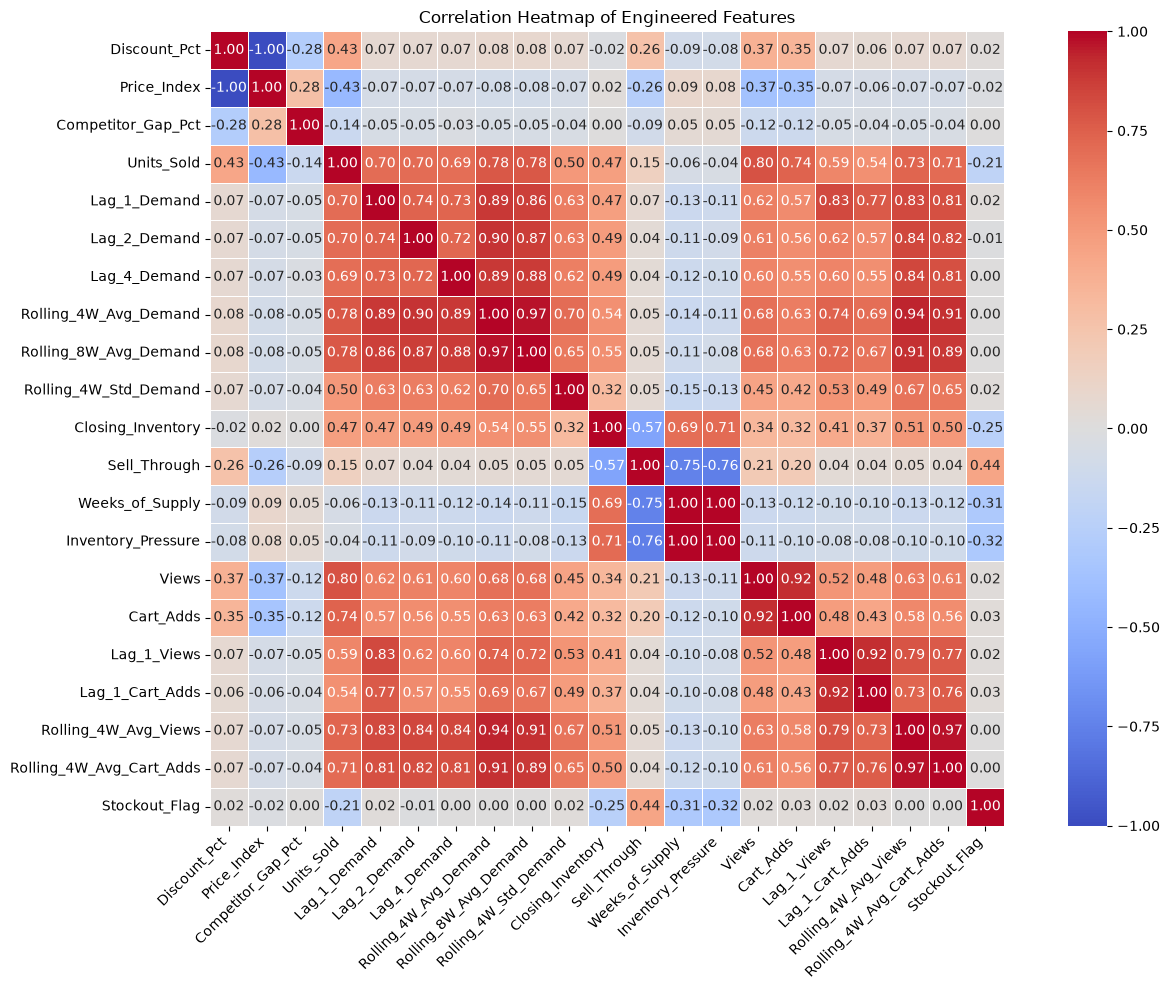

In [101]:
import seaborn as sns
import matplotlib.pyplot as plt

# ---------------------------------------------------------
# Feature Redundancy Heatmap
# ---------------------------------------------------------

plt.figure(figsize=(14, 10))

sns.heatmap(
    redundancy_corr,
    annot=True,
    fmt=".2f",
    cmap="coolwarm",
    center=0,
    square=True,
    linewidths=0.5
)
plt.xticks(rotation=45, ha="right")
plt.title("Correlation Heatmap of Engineered Features")
plt.tight_layout()

# Optional: save the chart
plt.savefig(
    "../outputs/charts/feature_engineering/feature_redundancy_heatmap.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

In [104]:
# ---------------------------------------------------------
# Highly Correlated Feature Pairs
# ---------------------------------------------------------

high_corr_pairs = []

for i in range(len(redundancy_corr.columns)):
    for j in range(i + 1, len(redundancy_corr.columns)):

        corr_value = redundancy_corr.iloc[i, j]

        if abs(corr_value) >= 0.85:

            high_corr_pairs.append({
                "Feature_1": redundancy_corr.columns[i],
                "Feature_2": redundancy_corr.columns[j],
                "Correlation": corr_value
            })

high_corr_pairs_df = pd.DataFrame(high_corr_pairs)

display(
    high_corr_pairs_df.sort_values(
        "Correlation",
        key=abs,
        ascending=False
    )
)

,Feature_1,Feature_2,Correlation
0,Discount_Pct,Price_Index,-1.00
12,Weeks_of_Supply,Inventory_Pressure,1.00
15,Rolling_4W_Avg_Views,Rolling_4W_Avg_Cart_Adds,0.97
7,Rolling_4W_Avg_Demand,Rolling_8W_Avg_Demand,0.97
8,Rolling_4W_Avg_Demand,Rolling_4W_Avg_Views,0.94
13,Views,Cart_Adds,0.92
14,Lag_1_Views,Lag_1_Cart_Adds,0.92
9,Rolling_4W_Avg_Demand,Rolling_4W_Avg_Cart_Adds,0.91
10,Rolling_8W_Avg_Demand,Rolling_4W_Avg_Views,0.91
3,Lag_2_Demand,Rolling_4W_Avg_Demand,0.90


### Final Redundancy Audit Interpretation

The updated correlation analysis confirms several expected relationships among
the engineered predictors.

- Discount_Pct and Price_Index are perfectly inversely related and contain the
  same pricing information.
- Weeks_of_Supply and Inventory_Pressure are effectively redundant.
- Rolling demand features are strongly correlated because they summarize similar
  recent demand history.
- Views and Cart_Adds, including their rolling versions, show strong correlation,
  indicating overlapping customer-interest signals.
- Units_Sold is moderately to strongly related to recent demand and engagement
  features, which is expected because it reflects realized demand in Week t.
- Stockout_Flag shows relatively weak linear correlation with most predictors,
  but it may still provide useful information about inventory-constrained sales.

Highly correlated features will be reviewed during model development rather than
removed automatically at the feature-engineering stage.

In [103]:
processed_path = (
    "../data/processed/"
    "smartmarkdown_feature_engineered.csv"
)

model_ready_df.to_csv(
    processed_path,
    index=False
)

print("Updated processed dataset saved successfully.")
print("Final Shape:", model_ready_df.shape)

Updated processed dataset saved successfully.
Final Shape: (3840, 35)


-------

## 12. Save Final Feature-Engineered Dataset

### Objective
Save the validated and feature-engineered modelling dataset so it can be reused
in later modelling notebooks without repeating the full feature-engineering process.

### Output
The processed dataset will be stored in the `data/processed` folder.

In [61]:
# ---------------------------------------------------------
# Save Feature-Engineered Dataset
# ---------------------------------------------------------

processed_path = (
    "../data/processed/"
    "smartmarkdown_feature_engineered.csv"
)

model_ready_df.to_csv(
    processed_path,
    index=False
)

print("Saved successfully:")
print(processed_path)
print("Shape:", model_ready_df.shape)

Saved successfully:
../data/processed/smartmarkdown_feature_engineered.csv
Shape: (3840, 31)


## 13. Feature Engineering Summary

- Created calendar features aligned to the future prediction week.
- Created leakage-safe demand lag features for 1, 2 and 4 weeks.
- Created 4-week and 8-week rolling demand features.
- Created recent demand variability using rolling standard deviation.
- Created pricing features including Price_Index, Competitor_Gap_Pct and Unit_Margin.
- Created inventory features including Sell_Through, Weeks_of_Supply and Inventory_Pressure.
- Created lagged and rolling customer-interest features using Views and Cart_Adds.
- Created Future_Latent_Demand as the next-week regression target.
- Removed only structurally incomplete rows created by lag, rolling and target shifting.
- Final modelling dataset contains 3,840 observations across 40 SKUs.
- No missing values remain.
- Feature redundancy was reviewed before modelling.

### Important Modelling Considerations

- Discount_Pct and Price_Index contain essentially the same information.
- Weeks_of_Supply and Inventory_Pressure are highly redundant.
- Several lag/rolling demand and customer-interest features are strongly correlated.
- Feature selection will therefore be model-dependent.
- Encoding and scaling must be fitted only on training data after chronological splitting.

**Next Stage:** Demand Regression